Importing the Dependencies

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [ ]:
from google.colab import files
uploaded=files.upload()
print(uploaded)

Saving winequalityN.csv to winequalityN (1).csv
{'winequalityN (1).csv': b'type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality\r\nwhite,7,0.27,0.36,20.7,0.045,45,170,1.001,3,0.45,8.8,6\r\nwhite,6.3,0.3,0.34,1.6,0.049,14,132,0.994,3.3,0.49,9.5,6\r\nwhite,8.1,0.28,0.4,6.9,0.05,30,97,0.9951,3.26,0.44,10.1,6\r\nwhite,7.2,0.23,0.32,8.5,0.058,47,186,0.9956,3.19,0.4,9.9,6\r\nwhite,7.2,0.23,0.32,8.5,0.058,47,186,0.9956,3.19,0.4,9.9,6\r\nwhite,8.1,0.28,0.4,6.9,0.05,30,97,0.9951,3.26,0.44,10.1,6\r\nwhite,6.2,0.32,0.16,7,0.045,30,136,0.9949,3.18,0.47,9.6,6\r\nwhite,7,0.27,0.36,20.7,0.045,45,170,1.001,3,0.45,8.8,6\r\nwhite,6.3,0.3,0.34,1.6,0.049,14,132,0.994,3.3,0.49,9.5,6\r\nwhite,8.1,0.22,0.43,1.5,0.044,28,129,0.9938,3.22,0.45,11,6\r\nwhite,8.1,0.27,0.41,1.45,0.033,11,63,0.9908,2.99,0.56,12,5\r\nwhite,8.6,0.23,0.4,4.2,0.035,17,109,0.9947,3.14,0.53,9.7,5\r\nwhite,7.9,0.18,0.37,1.2,0.04,16,75,0.992,3

In [ ]:
# loading the dataset to a Pandas DataFrame
wine_dataset = pd.read_csv('winequalityN.csv')

In [ ]:
# number of rows & columns in the dataset
wine_dataset.shape

(6497, 13)

In [ ]:
# first 5 rows of the dataset
wine_dataset.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [ ]:
# checking for missing values
wine_dataset.isnull().sum()

,0
type,0
fixed acidity,10
volatile acidity,8
citric acid,3
residual sugar,2
chlorides,2
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,9


Data Analysis and Visulaization

In [ ]:
# statistical measures of the dataset
wine_dataset.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6487.000000,6489.000000,6494.000000,6495.000000,6495.000000,6497.000000,6497.000000,6497.000000,6488.000000,6493.000000,6497.000000,6497.000000
mean,7.216579,0.339691,0.318722,5.444326,0.056042,30.525319,115.744574,0.994697,3.218395,0.531215,10.491801,5.818378
std,1.296750,0.164649,0.145265,4.758125,0.035036,17.749400,56.521855,0.002999,0.160748,0.148814,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


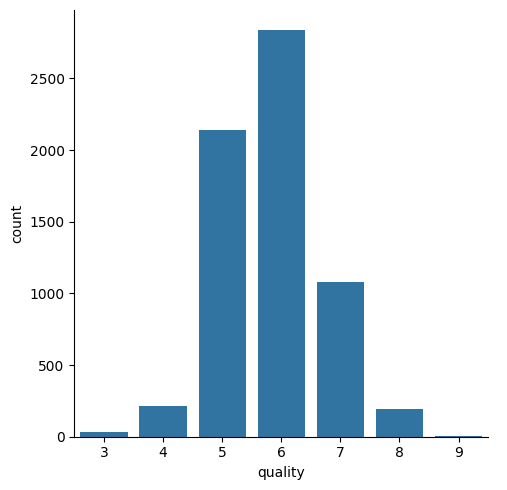

In [ ]:
# number of values for each quality
sns.catplot(x='quality', data = wine_dataset, kind = 'count')

<Axes: xlabel='quality', ylabel='volatile acidity'>

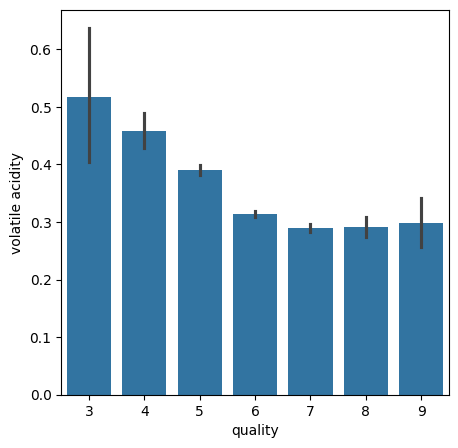

In [ ]:
# volatile acidity vs Quality
plot = plt.figure(figsize=(5,5))
sns.barplot(x='quality', y = 'volatile acidity', data = wine_dataset)

<Axes: xlabel='quality', ylabel='citric acid'>

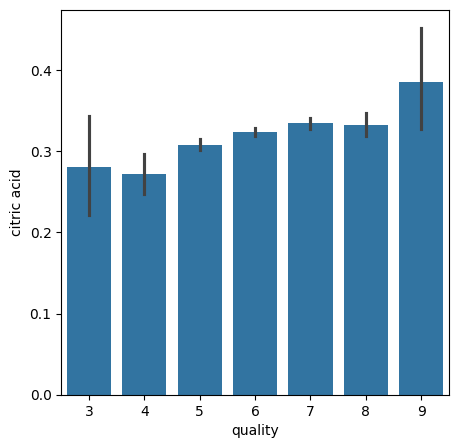

In [ ]:
# citric acid vs Quality
plot = plt.figure(figsize=(5,5))
sns.barplot(x='quality', y = 'citric acid', data = wine_dataset)

Correlation

1. Positive Correlation
2. Negative Correlation

In [17]:
correlation = wine_dataset.select_dtypes(include=['number']).corr()
print(correlation)

                      fixed acidity  volatile acidity  citric acid  \
fixed acidity              1.000000          0.220172     0.323736   
volatile acidity           0.220172          1.000000    -0.378061   
citric acid                0.323736         -0.378061     1.000000   
residual sugar            -0.112319         -0.196702     0.142486   
chlorides                  0.298421          0.377167     0.039315   
free sulfur dioxide       -0.283317         -0.353230     0.133437   
total sulfur dioxide      -0.329747         -0.414928     0.195218   
density                    0.459204          0.271193     0.096320   
pH                        -0.251814          0.260660    -0.328689   
sulphates                  0.300380          0.225476     0.057613   
alcohol                   -0.095603         -0.038248    -0.010433   
quality                   -0.077031         -0.265953     0.085706   

                      residual sugar  chlorides  free sulfur dioxide  \
fixed acidity    

In [27]:
wine_dataset['type'] = wine_dataset['type'].map({
    'red': 0,
    'white': 1
})

correlation = wine_dataset.corr()
print(correlation)

                          type  fixed acidity  volatile acidity  citric acid  \
type                  1.000000      -0.487241         -0.652875     0.187126   
fixed acidity        -0.487241       1.000000          0.220172     0.323736   
volatile acidity     -0.652875       0.220172          1.000000    -0.378061   
citric acid           0.187126       0.323736         -0.378061     1.000000   
residual sugar        0.349000      -0.112319         -0.196702     0.142486   
chlorides            -0.512622       0.298421          0.377167     0.039315   
free sulfur dioxide   0.471644      -0.283317         -0.353230     0.133437   
total sulfur dioxide  0.700357      -0.329747         -0.414928     0.195218   
density              -0.390645       0.459204          0.271193     0.096320   
pH                   -0.328727      -0.251814          0.260660    -0.328689   
sulphates            -0.486916       0.300380          0.225476     0.057613   
alcohol               0.032970      -0.0

In [28]:
print(wine_dataset.dtypes)

type                      int64
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object


In [29]:
print(wine_dataset.select_dtypes(include='object').columns)

Index([], dtype='object')


In [30]:
wine_dataset['type'] = wine_dataset['type'].replace({
    'red': 0,
    'white': 1
})

correlation = wine_dataset.corr(numeric_only=True)
print(correlation)

                          type  fixed acidity  volatile acidity  citric acid  \
type                  1.000000      -0.487241         -0.652875     0.187126   
fixed acidity        -0.487241       1.000000          0.220172     0.323736   
volatile acidity     -0.652875       0.220172          1.000000    -0.378061   
citric acid           0.187126       0.323736         -0.378061     1.000000   
residual sugar        0.349000      -0.112319         -0.196702     0.142486   
chlorides            -0.512622       0.298421          0.377167     0.039315   
free sulfur dioxide   0.471644      -0.283317         -0.353230     0.133437   
total sulfur dioxide  0.700357      -0.329747         -0.414928     0.195218   
density              -0.390645       0.459204          0.271193     0.096320   
pH                   -0.328727      -0.251814          0.260660    -0.328689   
sulphates            -0.486916       0.300380          0.225476     0.057613   
alcohol               0.032970      -0.0

In [32]:
correlation = wine_dataset.corr(numeric_only=True)
print(correlation)

                          type  fixed acidity  volatile acidity  citric acid  \
type                  1.000000      -0.487241         -0.652875     0.187126   
fixed acidity        -0.487241       1.000000          0.220172     0.323736   
volatile acidity     -0.652875       0.220172          1.000000    -0.378061   
citric acid           0.187126       0.323736         -0.378061     1.000000   
residual sugar        0.349000      -0.112319         -0.196702     0.142486   
chlorides            -0.512622       0.298421          0.377167     0.039315   
free sulfur dioxide   0.471644      -0.283317         -0.353230     0.133437   
total sulfur dioxide  0.700357      -0.329747         -0.414928     0.195218   
density              -0.390645       0.459204          0.271193     0.096320   
pH                   -0.328727      -0.251814          0.260660    -0.328689   
sulphates            -0.486916       0.300380          0.225476     0.057613   
alcohol               0.032970      -0.0

<Axes: >

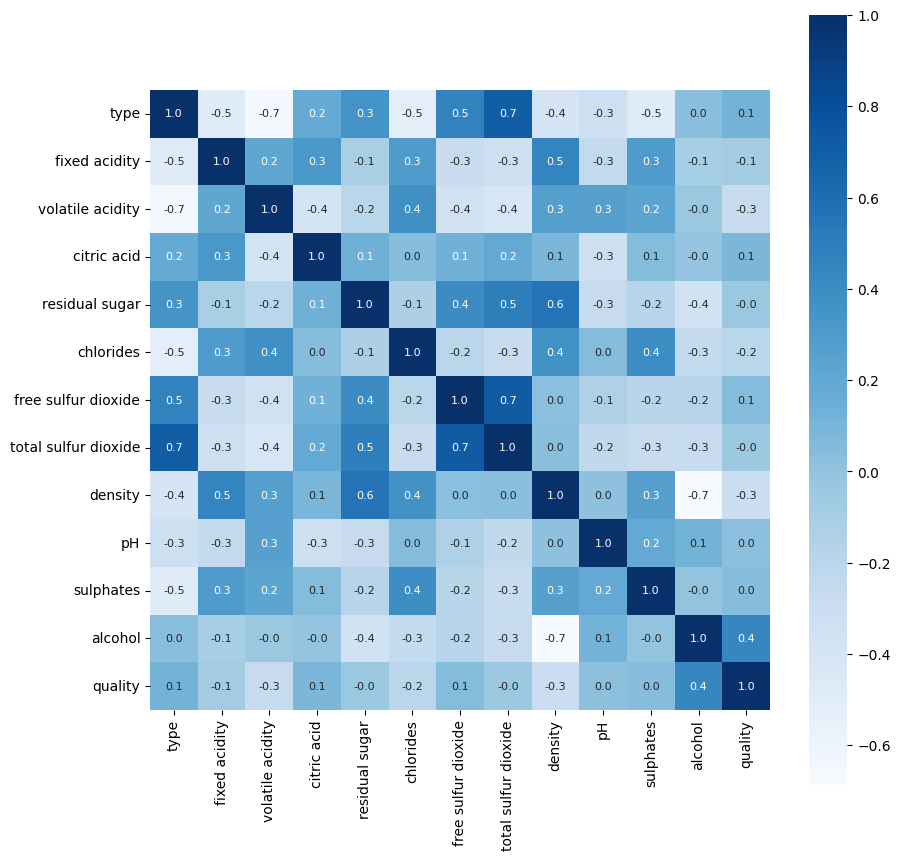

In [33]:
# constructing a heatmap to understand the correlation between the columns
plt.figure(figsize=(10,10))
sns.heatmap(correlation, cbar=True, square=True, fmt = '.1f', annot = True, annot_kws={'size':8}, cmap = 'Blues')

Data Preprocessing

In [34]:
# separate the data and Label
X = wine_dataset.drop('quality',axis=1)

In [35]:
print(X)

      type  fixed acidity  volatile acidity  citric acid  residual sugar  \
0        1            7.0             0.270         0.36            20.7   
1        1            6.3             0.300         0.34             1.6   
2        1            8.1             0.280         0.40             6.9   
3        1            7.2             0.230         0.32             8.5   
4        1            7.2             0.230         0.32             8.5   
...    ...            ...               ...          ...             ...   
6492     0            6.2             0.600         0.08             2.0   
6493     0            5.9             0.550         0.10             2.2   
6494     0            6.3             0.510         0.13             2.3   
6495     0            5.9             0.645         0.12             2.0   
6496     0            6.0             0.310         0.47             3.6   

      chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  \
0         

Label Binarizaton

In [36]:
Y = wine_dataset['quality'].apply(lambda y_value: 1 if y_value>=7 else 0)

In [22]:
print(Y)

0       0
1       0
2       0
3       0
4       0
       ..
6492    0
6493    0
6494    0
6495    0
6496    0
Name: quality, Length: 6497, dtype: int64


Train & Test Split

In [37]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=3)

In [38]:
print(Y.shape, Y_train.shape, Y_test.shape)

(6497,) (5197,) (1300,)


Model Training:

Random Forest Classifier

In [39]:
model = RandomForestClassifier()

In [40]:
model.fit(X_train, Y_train)

RandomForestClassifier()

Model Evaluation

Accuracy Score

In [41]:
# accuracy on test data
X_test_prediction = model.predict(X_test)
test_data_accuracy = accuracy_score(X_test_prediction, Y_test)

In [42]:
print('Accuracy : ', test_data_accuracy)

Accuracy :  0.8823076923076923


Building a Predictive System

In [50]:
print("Features used for training:")
print(X.columns)

print("\nNumber of features:", len(X.columns))

Features used for training:
Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol'],
      dtype='object')

Number of features: 12


In [51]:
print(model.n_features_in_)

12


In [45]:
print(X.columns)
print(len(X.columns))

Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol'],
      dtype='object')
12


In [46]:
red = 0
white = 1

In [52]:
input_data = (
    7.5, 0.5, 0.36, 6.1, 0.071,
    17.0, 102.0, 0.9978,
    3.35, 0.8, 10.5,
    0      # type = red
)

In [53]:
import pandas as pd

input_df = pd.DataFrame([input_data], columns=X.columns)

prediction = model.predict(input_df)

print(prediction)

[0]


In [54]:
X = wine_dataset.drop('quality', axis=1)
Y = wine_dataset['quality']

In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=2
)

model.fit(X_train, Y_train)

RandomForestClassifier()

In [56]:
import pandas as pd

input_df = pd.DataFrame(
    [input_data],
    columns=X.columns
)

prediction = model.predict(input_df)

if prediction[0] == 1:
    print("Good Quality Wine")
else:
    print("Bad Quality Wine")

Bad Quality Wine
